# TWI and Soil Covariates

Covariates for the RCR yield model: TWI from USGS 3DEP (1 m) and drainage class from SSURGO (dominant component).
All layers are saved on the 3 m RCR grid (PlanetScope) for each field, using the field boundaries from the polygons folder.
The last section puts yield, RCR, TWI and drainage class in one table for the model.

Input (uploaded): the cleaned yield zips (SC2_2025.zip, SC4_to_SC8.zip), the RCR detections zip, and the polygons zip

In [1]:
!pip install -q geopandas rasterio rioxarray py3dep pysheds

In [2]:
import os, glob, zipfile, shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
import rioxarray
import requests
import py3dep
from rasterio.enums import Resampling
from rasterio.features import rasterize
from shapely.geometry import MultiPoint
from shapely import wkt as shapely_wkt
from pysheds.grid import Grid

#pysheds uses np.in1d, which was removed in newer numpy
if not hasattr(np, "in1d"):
    np.in1d = np.isin

In [3]:
cell = 3            #grid size (m), same as the RCR maps (PlanetScope)
buffer_cells = 67   #67 cells x 3 m = 201 m buffer so upslope area outside the field is counted
buffer_m = buffer_cells * cell

sda_url = "https://sdmdataaccess.sc.egov.usda.gov/Tabular/post.rest"

## Importing Files

In [6]:
#Upload the zips: cleaned yield (SC2_2025, SC4_to_SC8, SC2 2023), RCR detections, and polygons
#from google.colab import files
#uploaded = files.upload()
uploaded = sorted(glob.glob("*.zip"))

In [7]:
shutil.rmtree("fields", ignore_errors=True)

for zip_name in uploaded:
    folder = zip_name.replace(".zip", "").replace(" ", "_")
    zipfile.ZipFile(zip_name).extractall(f"fields/{folder}")

#the boundary folders have their own zip files inside
for inner_zip in glob.glob("fields/**/Boun_*.zip", recursive=True):
    zipfile.ZipFile(inner_zip).extractall(os.path.dirname(inner_zip))

shapefiles = sorted(glob.glob("fields/**/*_cleaned.shp", recursive=True))

#boundary and RCR map for each field ID (SC2, SC4, ...)
boundary_path = {}
for path in glob.glob("fields/**/Boun_*.shp", recursive=True):
    field_id = os.path.basename(path).replace("Boun_", "").replace(".shp", "")
    boundary_path[field_id] = path

#RCR maps by field and year (SC2_2025, SC2_2023, ...), since SC2 has a map for both years
rcr_path = {}
rcr_class_path = {}
for path in glob.glob("fields/**/*_rcr_probability.tif", recursive=True):
    parts = os.path.basename(path).split("_")   #SC2_2025_20250908_rcr_probability.tif
    field_year = parts[0] + "_" + parts[1]
    rcr_path[field_year] = path
    rcr_class_path[field_year] = path.replace("_probability.tif", "_classified.tif")

print("yield files:", [os.path.basename(s) for s in shapefiles])
print("RCR maps:", sorted(rcr_path))

yield files: ['SC4_2025_cleaned.shp', 'SC5_2025_cleaned.shp', 'SC6_2025_cleaned.shp', 'SC7_2025_cleaned.shp', 'SC8_2025_cleaned.shp', 'SC2_2025_cleaned.shp']
RCR maps: ['SC2_2025', 'SC4_2025', 'SC5_2025', 'SC6_2025', 'SC7_2025', 'SC8_2025']


## Field Boundaries

In [8]:
#Field boundaries from the polygons folder (Boun_<field>.shp)
field_names = []
field_id = {}
yield_path = {}
outlines = {}
utm_crs = {}

for shp in shapefiles:
    fid = os.path.basename(shp).split("_")[0]   #SC4_2025_cleaned.shp -> SC4

    #harvest year from the yield monitor dates, so SC2 (2023) and SC2_2025 stay apart
    harvest_dates = pd.to_datetime(gpd.read_file(shp, ignore_geometry=True)["IsoTime"])
    name = fid + "_" + str(harvest_dates.dt.year.mode()[0])

    if fid not in boundary_path or name not in rcr_path:
        print(name, "skipped, no boundary or RCR map for this year")
        continue

    #use the same CRS as the RCR map
    with rasterio.open(rcr_path[name]) as src:
        crs = src.crs.to_string()

    boundary = gpd.read_file(boundary_path[fid])
    if boundary.crs is None:   #Boun_SC2 has no .prj file, coordinates are lat/lon
        boundary = boundary.set_crs(4326)
    boundary = boundary.to_crs(crs)

    field_names.append(name)
    field_id[name] = fid
    yield_path[name] = shp
    utm_crs[name] = crs
    outlines[name] = boundary.geometry.union_all()

    os.makedirs(f"outputs/{name}", exist_ok=True)
    gpd.GeoDataFrame(geometry=[outlines[name]], crs=crs).to_file(f"outputs/{name}/field_outline.gpkg")
    print(name, round(outlines[name].area / 4046.86), "acres")

SC4_2025 128 acres
SC5_2025 99 acres
SC6_2025 70 acres
SC7_2025 50 acres
SC8_2025 184 acres
SC2_2025 67 acres


In [9]:
#The RCR probability map is the template grid. Every layer is saved on this grid
rcr_grid = {}

for name in field_names:
    with rasterio.open(rcr_path[name]) as src:
        rcr_grid[name] = src.meta.copy()
        print(name, src.res, src.width, "x", src.height, "date:", os.path.basename(src.name).split("_")[2])

SC4_2025 (3.0, 3.0) 232 x 263 date: 20250910
SC5_2025 (3.0, 3.0) 264 x 197 date: 20250908
SC6_2025 (3.0, 3.0) 129 x 266 date: 20250904
SC7_2025 (3.0, 3.0) 261 x 113 date: 20250901
SC8_2025 (3.0, 3.0) 398 x 275 date: 20250820
SC2_2025 (3.0, 3.0) 126 x 256 date: 20250908


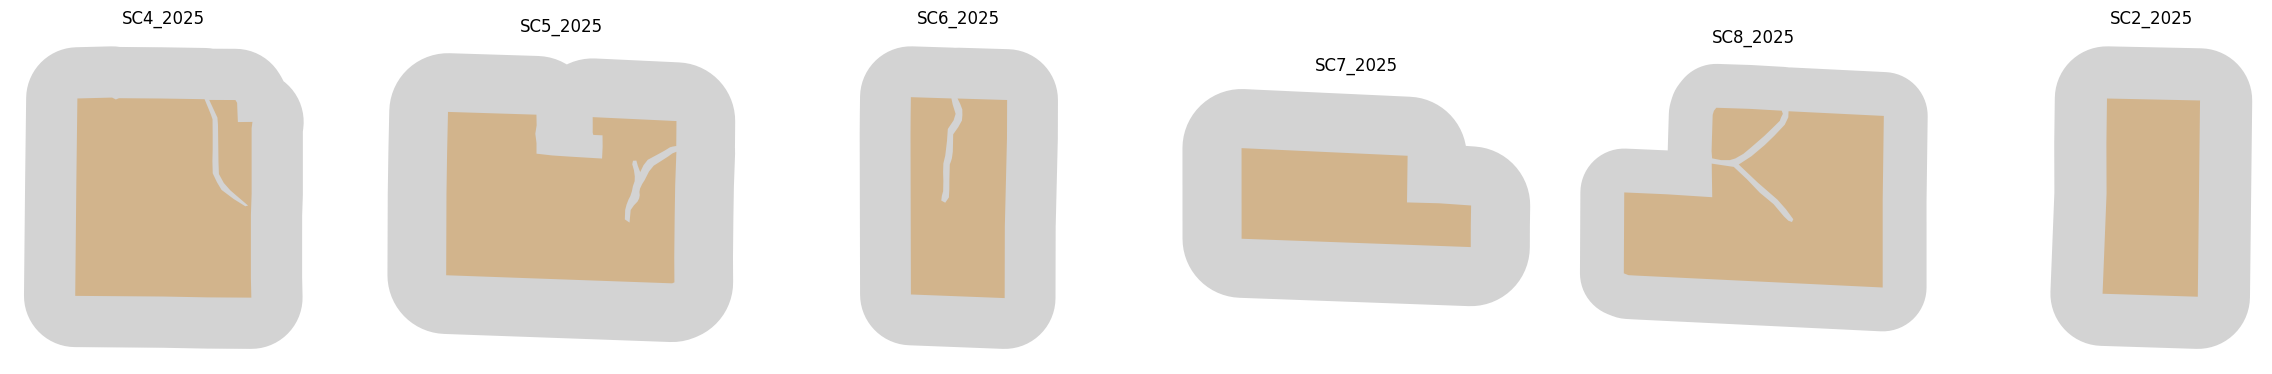

In [10]:
fig, axes = plt.subplots(1, len(field_names), figsize=(4 * len(field_names), 4))

for ax, name in zip(axes, field_names):
    gpd.GeoSeries([outlines[name].buffer(buffer_m)]).plot(ax=ax, color="lightgrey")
    gpd.GeoSeries([outlines[name]]).plot(ax=ax, color="tan")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Elevation (3DEP)

1 m DEM averaged to 3 m, on the RCR grid plus a 201 m buffer.

In [11]:
for name in field_names:
    area = outlines[name].buffer(buffer_m)
    avail = py3dep.check_3dep_availability(area.bounds, crs=utm_crs[name])
    print(name, "1 m available:", avail.get("1m"))

SC4_2025 1 m available: True
SC5_2025 1 m available: True
SC6_2025 1 m available: True
SC7_2025 1 m available: True
SC8_2025 1 m available: True
SC2_2025 1 m available: True


In [12]:
for name in field_names:
    crs = utm_crs[name]
    grid = rcr_grid[name]

    #RCR grid plus the buffer on every side, so the DEM cells line up with the RCR cells
    width = grid["width"] + 2 * buffer_cells
    height = grid["height"] + 2 * buffer_cells
    left = grid["transform"].c - buffer_m
    top = grid["transform"].f + buffer_m
    dem_transform = rasterio.transform.from_origin(left, top, cell, cell)

    #extra 50 m so the edges aren't empty after reprojecting
    download_box = (left - 50, top - height * cell - 50, left + width * cell + 50, top + 50)

    avail = py3dep.check_3dep_availability(download_box, crs=crs)
    resolution = 1 if avail.get("1m") is True else 10

    dem = py3dep.get_dem(download_box, resolution, crs=crs)
    dem = dem.rio.reproject(crs, transform=dem_transform, shape=(height, width), resampling=Resampling.average)

    #filling gaps, otherwise flow routing breaks
    missing = int(dem.isnull().sum())
    if missing > 0:
        dem = dem.rio.write_nodata(np.nan, encoded=False).rio.interpolate_na()

    dem.rio.to_raster(f"outputs/{name}/dem.tif")
    print(name, f"{resolution} m source,", dem.shape, "grid,", missing, "gaps filled")

SC4_2025 1 m source, (397, 366) grid, 0 gaps filled
SC5_2025 1 m source, (331, 398) grid, 0 gaps filled
SC6_2025 1 m source, (400, 263) grid, 0 gaps filled
SC7_2025 1 m source, (247, 395) grid, 0 gaps filled
SC8_2025 1 m source, (409, 532) grid, 0 gaps filled
SC2_2025 1 m source, (390, 260) grid, 0 gaps filled


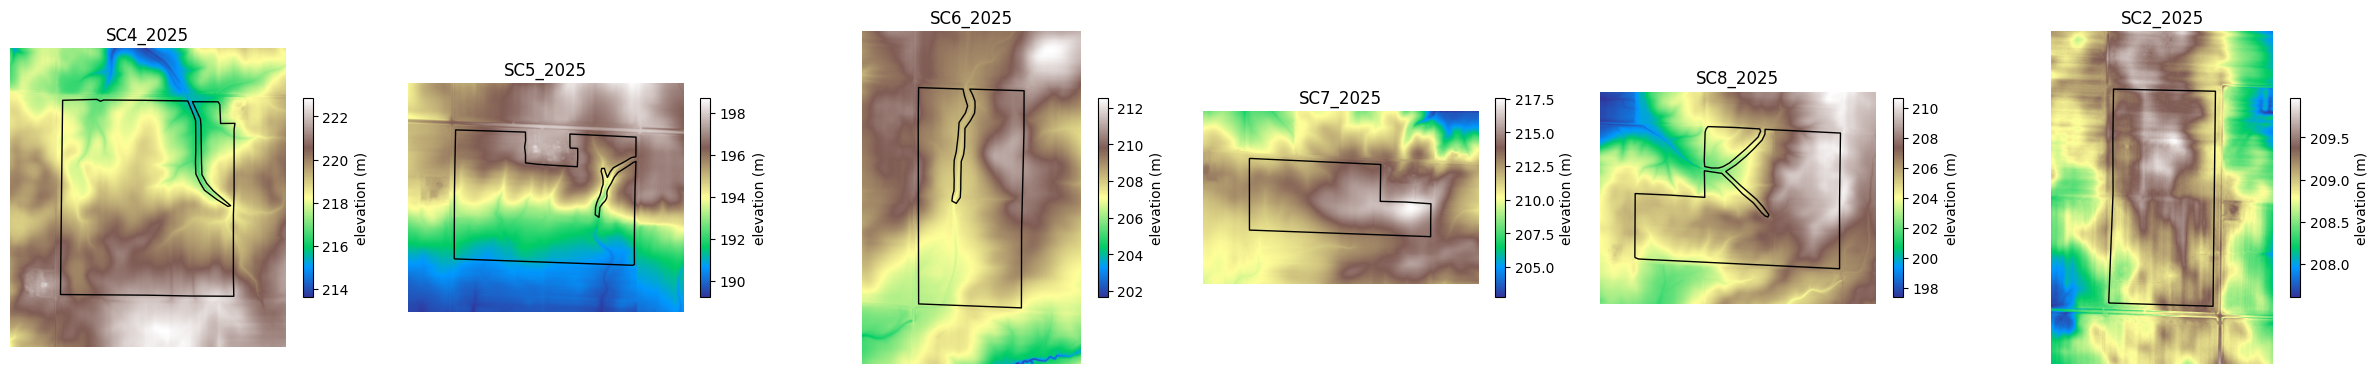

In [13]:
fig, axes = plt.subplots(1, len(field_names), figsize=(4 * len(field_names), 4))

for ax, name in zip(axes, field_names):
    with rasterio.open(f"outputs/{name}/dem.tif") as src:
        elevation = src.read(1)
        b = src.bounds
    im = ax.imshow(elevation, cmap="terrain", extent=[b.left, b.right, b.bottom, b.top])
    gpd.GeoSeries([outlines[name]]).boundary.plot(ax=ax, color="black", linewidth=1)
    ax.set_title(name)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.6, label="elevation (m)")

plt.tight_layout()
plt.show()

## TWI

TWI = ln(a / tan β), where a is the upslope area per unit contour width and β is the slope.
Pits and depressions are filled before routing flow (D8).

In [14]:
for name in field_names:
    dem_path = f"outputs/{name}/dem.tif"

    #flow direction and accumulation
    grid = Grid.from_raster(dem_path)
    dem = grid.read_raster(dem_path)
    filled = grid.fill_pits(dem)
    filled = grid.fill_depressions(filled)
    filled = grid.resolve_flats(filled)
    fdir = grid.flowdir(filled)
    acc = np.array(grid.accumulation(fdir), dtype="float64")

    #slope from the unfilled DEM
    with rasterio.open(dem_path) as src:
        elevation = src.read(1).astype("float64")
        meta = src.meta.copy()
    dz_dy, dz_dx = np.gradient(elevation, cell)
    tan_slope = np.maximum(np.sqrt(dz_dx**2 + dz_dy**2), 0.001)   #floor to avoid dividing by 0 on flat ground

    twi = np.log((acc + 1) * cell / tan_slope)

    meta.update(dtype="float32", nodata=-9999)
    with rasterio.open(f"outputs/{name}/twi.tif", "w", **meta) as dst:
        dst.write(twi.astype("float32"), 1)

    print(name, "TWI median:", round(np.median(twi), 1))

SC4_2025 TWI median: 7.1
SC5_2025 TWI median: 7.2
SC6_2025 TWI median: 7.2
SC7_2025 TWI median: 6.9
SC8_2025 TWI median: 7.1
SC2_2025 TWI median: 7.5


In [15]:
#Cutting TWI down to the RCR grid (the buffer was only for flow routing)
for name in field_names:
    twi = rioxarray.open_rasterio(f"outputs/{name}/twi.tif").squeeze()
    rcr = rioxarray.open_rasterio(rcr_path[name]).squeeze()

    twi_3m = twi.rio.reproject_match(rcr)
    twi_3m.rio.to_raster(f"outputs/{name}/twi_3m.tif")
    print(name, twi_3m.shape, "same as RCR:", twi_3m.shape == rcr.shape)

SC4_2025 (263, 232) same as RCR: True
SC5_2025 (197, 264) same as RCR: True
SC6_2025 (266, 129) same as RCR: True
SC7_2025 (113, 261) same as RCR: True
SC8_2025 (275, 398) same as RCR: True
SC2_2025 (256, 126) same as RCR: True


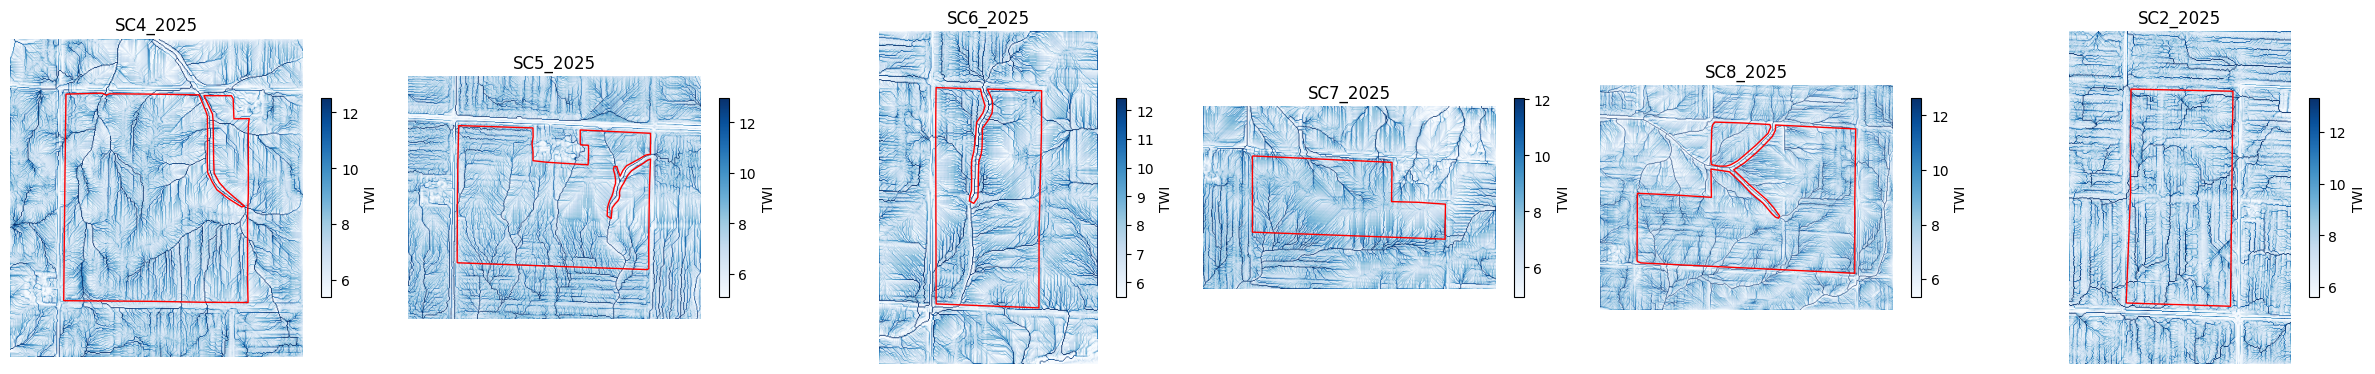

In [16]:
#darker blue = wetter
fig, axes = plt.subplots(1, len(field_names), figsize=(4 * len(field_names), 4))

for ax, name in zip(axes, field_names):
    with rasterio.open(f"outputs/{name}/twi.tif") as src:
        twi = src.read(1)
        b = src.bounds
    low, high = np.percentile(twi, [2, 98])
    im = ax.imshow(twi, cmap="Blues", vmin=low, vmax=high, extent=[b.left, b.right, b.bottom, b.top])
    gpd.GeoSeries([outlines[name]]).boundary.plot(ax=ax, color="red", linewidth=1)
    ax.set_title(name)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.6, label="TWI")

plt.tight_layout()
plt.show()

## Soil (SSURGO)

From USDA Soil Data Access. For each map unit, using the dominant component (highest comppct_r).
Only drainage class is kept: clay and water capacity come from the same map units and carry almost the same information.

In [17]:
#Soil map unit polygons overlapping each field
soil_polygons = {}

for name in field_names:
    area = gpd.GeoSeries([outlines[name].buffer(20)], crs=utm_crs[name]).to_crs(4326)
    area_wkt = area.iloc[0].simplify(0.0001).wkt

    query = f"""
        SELECT mupolygonkey, mukey, mupolygongeo.STAsText() AS wkt
        FROM mupolygon
        WHERE mupolygonkey IN (
            SELECT * FROM SDA_Get_Mupolygonkey_from_intersection_with_WktWgs84('{area_wkt}'))
    """
    result = requests.post(sda_url, data={"query": query, "format": "JSON+COLUMNNAME"}, timeout=120).json()
    if "Table" not in result:
        print(name, "no soil polygons returned")
        continue

    table = pd.DataFrame(result["Table"][1:], columns=result["Table"][0])
    polygons = gpd.GeoDataFrame(table[["mupolygonkey", "mukey"]],
                                geometry=table["wkt"].apply(shapely_wkt.loads), crs=4326)
    polygons = gpd.clip(polygons.to_crs(utm_crs[name]), outlines[name].buffer(20))

    soil_polygons[name] = polygons
    print(name, polygons["mukey"].nunique(), "map units")

SC4_2025 6 map units
SC5_2025 5 map units
SC6_2025 3 map units
SC7_2025 3 map units
SC8_2025 5 map units
SC2_2025 2 map units


In [18]:
#Dominant component of each map unit
all_mukeys = sorted(set(pd.concat([soil_polygons[name]["mukey"] for name in soil_polygons])))
mukey_list = ",".join(f"'{m}'" for m in all_mukeys)

query = f"""
    SELECT mukey, cokey, compname, comppct_r, drainagecl
    FROM component
    WHERE mukey IN ({mukey_list})
"""
result = requests.post(sda_url, data={"query": query, "format": "JSON+COLUMNNAME"}, timeout=120).json()
components = pd.DataFrame(result["Table"][1:], columns=result["Table"][0])
components["comppct_r"] = pd.to_numeric(components["comppct_r"])

dominant = components.sort_values("comppct_r", ascending=False).drop_duplicates("mukey")
dominant

,mukey,cokey,compname,comppct_r,drainagecl
10,179006,27820309,Parr,100,Well drained
5,179001,27820252,Catlin,99,Moderately well drained
4,178998,27820269,Flanagan,97,Somewhat poorly drained
13,179031,27820256,Dana,97,Moderately well drained
16,179032,27820259,Dana,96,Moderately well drained
20,1913939,27813808,Flanagan,95,Somewhat poorly drained
0,178997,27820229,Drummer,94,Poorly drained
11,179029,27820240,Raub,94,Somewhat poorly drained
17,1913937,27813805,Drummer,94,Poorly drained
7,179002,27820264,Elburn,93,Somewhat poorly drained


In [19]:
#Drainage class: the text label is the category used in the model
#the number code is only so it can be saved in a raster (1 = wettest)
drainage_order = {
    "Very poorly drained": 1,
    "Poorly drained": 2,
    "Somewhat poorly drained": 3,
    "Moderately well drained": 4,
    "Well drained": 5,
    "Somewhat excessively drained": 6,
    "Excessively drained": 7,
}
drainage_label = {code: label for label, code in drainage_order.items()}

dominant["drainage_code"] = dominant["drainagecl"].map(drainage_order)

soil_columns = ["mukey", "compname", "comppct_r", "drainagecl", "drainage_code"]

for name in soil_polygons:
    soil_polygons[name] = soil_polygons[name].merge(dominant[soil_columns], on="mukey", how="left")
    soil_polygons[name].to_file(f"outputs/{name}/soil_polygons.gpkg")

dominant[soil_columns]

,mukey,compname,comppct_r,drainagecl,drainage_code
10,179006,Parr,100,Well drained,5
5,179001,Catlin,99,Moderately well drained,4
4,178998,Flanagan,97,Somewhat poorly drained,3
13,179031,Dana,97,Moderately well drained,4
16,179032,Dana,96,Moderately well drained,4
20,1913939,Flanagan,95,Somewhat poorly drained,3
0,178997,Drummer,94,Poorly drained,2
11,179029,Raub,94,Somewhat poorly drained,3
17,1913937,Drummer,94,Poorly drained,2
7,179002,Elburn,93,Somewhat poorly drained,3


In [20]:
#Rasterizing drainage class onto the RCR grid
for name in soil_polygons:
    meta = rcr_grid[name].copy()
    meta.update(dtype="float32", nodata=-9999)

    polygons = soil_polygons[name]
    has_value = polygons["drainage_code"].notna()
    layer = rasterize(zip(polygons.geometry[has_value], polygons["drainage_code"][has_value]),
                      out_shape=(meta["height"], meta["width"]), transform=meta["transform"],
                      fill=-9999, dtype="float32")

    with rasterio.open(f"outputs/{name}/drainage_class.tif", "w", **meta) as dst:
        dst.write(layer, 1)

    print(name, "saved")

SC4_2025 saved
SC5_2025 saved
SC6_2025 saved
SC7_2025 saved
SC8_2025 saved
SC2_2025 saved


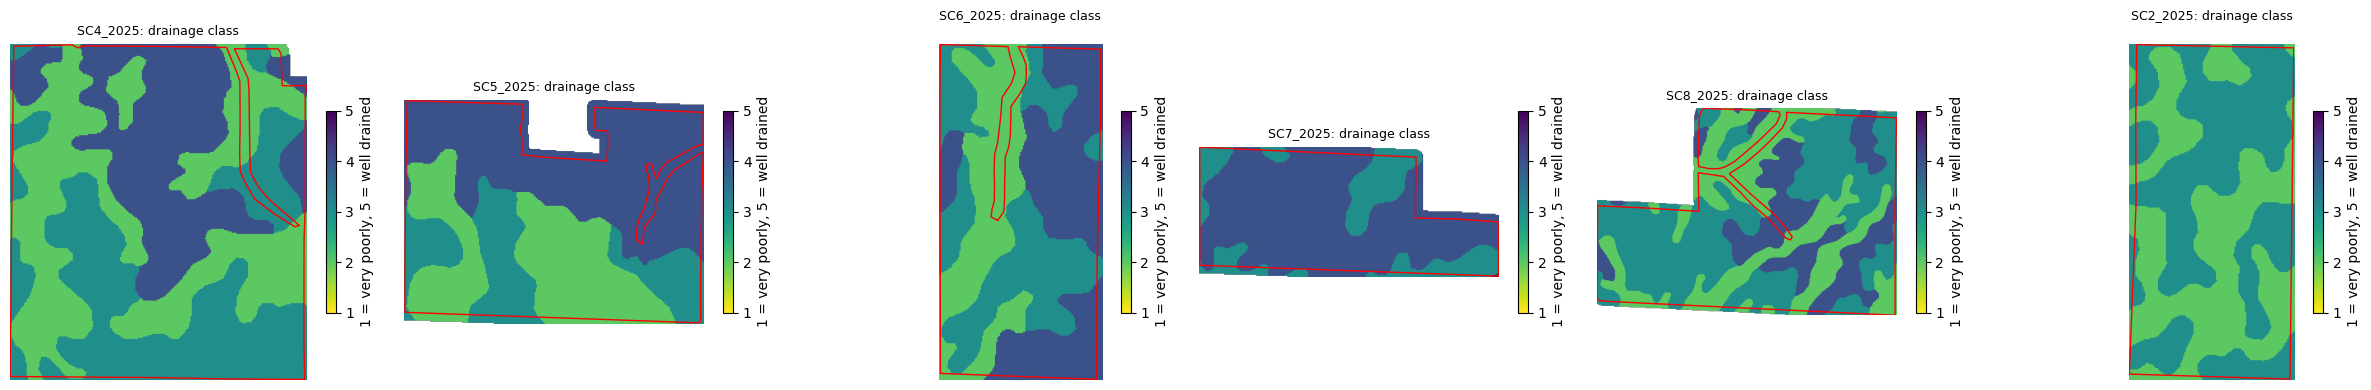

In [21]:
fig, axes = plt.subplots(1, len(soil_polygons), figsize=(4 * len(soil_polygons), 4))

for ax, name in zip(axes, soil_polygons):
    with rasterio.open(f"outputs/{name}/drainage_class.tif") as src:
        layer = src.read(1)
        b = src.bounds
    layer = np.where(layer == -9999, np.nan, layer)
    im = ax.imshow(layer, cmap="viridis_r", vmin=1, vmax=5, extent=[b.left, b.right, b.bottom, b.top])
    gpd.GeoSeries([outlines[name]]).boundary.plot(ax=ax, color="red", linewidth=1)
    ax.set_title(f"{name}: drainage class", fontsize=9)
    ax.axis("off")
    plt.colorbar(im, ax=ax, shrink=0.6, label="1 = very poorly, 5 = well drained")

plt.tight_layout()
plt.show()

## Summary

Inside the field boundary only (the buffer was just for TWI).

In [22]:
rows = []

for name in soil_polygons:
    with rasterio.open(f"outputs/{name}/twi_3m.tif") as src:
        twi = src.read(1)
        transform = src.transform
    with rasterio.open(f"outputs/{name}/drainage_class.tif") as src:
        drainage = src.read(1)
    with rasterio.open(rcr_path[name]) as src:
        rcr_prob = src.read(1, masked=True)
    with rasterio.open(rcr_class_path[name]) as src:
        rcr_class = src.read(1, masked=True)

    inside = rasterize([(outlines[name], 1)], out_shape=twi.shape, transform=transform, fill=0).astype(bool)
    has_soil = inside & (drainage != -9999)
    has_rcr = inside & ~np.ma.getmaskarray(rcr_prob)

    #main soil = component covering the most area in the field
    in_field = gpd.clip(soil_polygons[name], outlines[name])
    main_soil = in_field.assign(area=in_field.area).groupby("compname")["area"].sum().idxmax()

    rows.append({
        "field": name,
        "RCR image date": os.path.basename(rcr_path[name]).split("_")[2],
        "acres": round(outlines[name].area / 4046.86),
        "TWI median": round(float(np.median(twi[inside])), 1),
        "TWI 90th pct": round(float(np.percentile(twi[inside], 90)), 1),
        "% poorly drained": round(100 * float(np.mean(drainage[has_soil] <= 2)), 1),
        "RCR prob (mean)": round(float(rcr_prob.data[has_rcr].mean()), 2),
        "% RCR (classified)": round(100 * float(np.mean(rcr_class.data[has_rcr] == 1)), 1),
        "main soil": main_soil,
    })

summary = pd.DataFrame(rows)
summary.to_csv("outputs/covariate_summary.csv", index=False)
summary

,field,RCR image date,acres,TWI median,TWI 90th pct,% poorly drained,RCR prob (mean),% RCR (classified),main soil
0,SC4_2025,20250910,128,7.1,9.6,37.1,0.37,33.7,Drummer
1,SC5_2025,20250908,99,7.1,9.6,33.3,0.43,41.9,Drummer
2,SC6_2025,20250904,70,7.3,9.7,25.9,0.30,25.4,Dana
3,SC7_2025,20250901,50,7.1,8.9,0.0,0.61,62.0,Dana
4,SC8_2025,20250820,184,7.2,9.6,28.6,0.33,30.2,Raub
5,SC2_2025,20250908,67,7.5,10.2,46.1,0.55,54.9,Flanagan


## Check: TWI by Drainage Class

If both layers are right, mean TWI should go up as drainage gets poorer.

In [23]:
rows = []

for name in soil_polygons:
    with rasterio.open(f"outputs/{name}/twi_3m.tif") as src:
        twi = src.read(1)
        transform = src.transform
    with rasterio.open(f"outputs/{name}/drainage_class.tif") as src:
        drainage = src.read(1)

    inside = rasterize([(outlines[name], 1)], out_shape=twi.shape, transform=transform, fill=0).astype(bool)

    for code in np.unique(drainage[inside & (drainage != -9999)]):
        cells = inside & (drainage == code)
        rows.append({"field": name,
                     "drainage class": drainage_label[int(code)],
                     "mean TWI": round(float(twi[cells].mean()), 2),
                     "% of field": round(100 * cells.sum() / inside.sum(), 1)})

twi_by_drainage = pd.DataFrame(rows)
twi_by_drainage

,field,drainage class,mean TWI,% of field
0,SC4_2025,Poorly drained,7.88,37.1
1,SC4_2025,Somewhat poorly drained,7.42,33.7
2,SC4_2025,Moderately well drained,7.38,29.2
3,SC5_2025,Poorly drained,7.72,33.3
4,SC5_2025,Somewhat poorly drained,7.50,22.0
5,SC5_2025,Moderately well drained,7.34,44.8
6,SC6_2025,Poorly drained,8.18,25.9
7,SC6_2025,Somewhat poorly drained,7.72,36.7
8,SC6_2025,Moderately well drained,7.33,37.4
9,SC7_2025,Somewhat poorly drained,7.49,23.0


## Model Table

One row per 3 m cell inside the field: yield, RCR, TWI and drainage class.
Yield is the mean of the cleaned yield points that fall in each cell. Cells with no yield point are left out.

In [24]:
tables = []

for name in field_names:
    meta = rcr_grid[name]
    transform = meta["transform"]

    #mean yield of the points in each 3 m cell
    points = gpd.read_file(yield_path[name]).to_crs(utm_crs[name])
    rows, cols = rasterio.transform.rowcol(transform, points.geometry.x, points.geometry.y)
    points["row"] = rows
    points["col"] = cols
    cell_yield = points.groupby(["row", "col"])["yield_bu"].agg(["mean", "count"]).reset_index()
    cell_yield.columns = ["row", "col", "yield_bu", "n_points"]

    #all layers on the same grid
    with rasterio.open(rcr_path[name]) as src:
        rcr_prob = src.read(1, masked=True).filled(np.nan)
    with rasterio.open(rcr_class_path[name]) as src:
        rcr_class = src.read(1, masked=True).astype("float32").filled(np.nan)
    with rasterio.open(f"outputs/{name}/twi_3m.tif") as src:
        twi = src.read(1)
    with rasterio.open(f"outputs/{name}/drainage_class.tif") as src:
        drainage = src.read(1)

    inside = rasterize([(outlines[name], 1)], out_shape=twi.shape, transform=transform, fill=0).astype(bool)

    #keep cells inside the boundary that have a yield value
    cell_yield = cell_yield[(cell_yield["row"] >= 0) & (cell_yield["row"] < meta["height"]) &
                            (cell_yield["col"] >= 0) & (cell_yield["col"] < meta["width"])]
    r = cell_yield["row"].values
    c = cell_yield["col"].values
    cell_yield = cell_yield[inside[r, c]]
    r = cell_yield["row"].values
    c = cell_yield["col"].values

    xs, ys = rasterio.transform.xy(transform, r, c)
    table = pd.DataFrame({
        "field": name,
        "x": xs,
        "y": ys,
        "yield_bu": cell_yield["yield_bu"].values,
        "n_points": cell_yield["n_points"].values,
        "rcr_prob": rcr_prob[r, c],
        "rcr_class": rcr_class[r, c],
        "twi": twi[r, c],
        "drainage_class": pd.Series(drainage[r, c]).map(drainage_label).values,
    })
    table = table.dropna(subset=["rcr_prob", "drainage_class"])
    tables.append(table)
    print(name, len(table), "cells with yield")

model_table = pd.concat(tables, ignore_index=True)
model_table.to_csv("outputs/model_table_3m.csv", index=False)
model_table.head()

SC4_2025 16053 cells with yield
SC5_2025 12237 cells with yield
SC6_2025 8984 cells with yield
SC7_2025 6559 cells with yield
SC8_2025 23389 cells with yield
SC2_2025 9623 cells with yield


,field,x,y,yield_bu,n_points,rcr_prob,rcr_class,twi,drainage_class
0,SC4_2025,335218.5,4390951.5,42.682186,2,0.872836,1.0,8.673522,Somewhat poorly drained
1,SC4_2025,335221.5,4390951.5,42.582116,2,0.804196,1.0,8.488344,Somewhat poorly drained
2,SC4_2025,335224.5,4390951.5,41.817772,2,0.980369,1.0,13.531726,Somewhat poorly drained
3,SC4_2025,335236.5,4390951.5,40.594535,2,0.987588,1.0,7.180243,Somewhat poorly drained
4,SC4_2025,335239.5,4390951.5,38.892990,1,0.990745,1.0,7.635631,Somewhat poorly drained


In [25]:
!zip -q -r twi_soil_layers.zip outputs

from google.colab import files
files.download("twi_soil_layers.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>